# Q1 · Part C (experiments) — learning rate, feature scaling, regularisation, under/over-fitting

These experiments provide the evidence for the **Discussion** section of the report.
Run `02_Q1_Implementation.ipynb` first (it saves the configuration used here).

In [1]:
# ---- Project setup: finds the project root automatically ----
import os, sys, json, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

def find_root():
    start = Path(os.environ.get("LAB_ROOT", Path.cwd())).resolve()
    for p in [start, *start.parents]:
        if (p / "requirements.txt").exists() and (p / "src").exists():
            return p
    raise RuntimeError("Project root not found. Open this notebook from inside the Prog_for_AI_Lab folder.")

ROOT = find_root()
sys.path.insert(0, str(ROOT / "src"))
print("Project root:", ROOT)

Project root: C:\Users\hp\Desktop\Prog_for_AI_Lab\Prog_for_AI_Lab


In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from linreg_scratch import *
from lab_utils import save_json, load_json, savefig
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

cfg = load_json(ROOT / "results" / "q1" / "results.json")["config"]
ALPHA, LAMBDA, N_ITERS, SEED, TEST_SIZE, SCALING = cfg["alpha"], cfg["lambda"], cfg["n_iters"], cfg["seed"], cfg["test_size"], cfg["scaling"]
DATA_FILE, TARGET_COL, DROP_COLS = None, None, []     # keep identical to notebook 02 if you changed them there
print(cfg)

X_df, y_s, path, raw = load_regression_data(ROOT / "data" / "q1", DATA_FILE, TARGET_COL, DROP_COLS)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_df.values.astype(float), y_s.values.astype(float), test_size=TEST_SIZE, random_state=SEED)

def prepare(method, Xtr=X_train_raw, Xte=X_test_raw):
    sc = fit_scaler(Xtr, method)
    return add_bias(apply_scaler(Xtr, sc)), add_bias(apply_scaler(Xte, sc)), sc

Xtr, Xte, sc = prepare(SCALING)
EXP = {}

{'scaling': 'standard', 'alpha': 0.1, 'lambda': 1.0, 'n_iters': 2000, 'test_size': 0.2, 'seed': 42}


## Experiment 1 — Effect of the learning rate α
Same data, same λ, only α changes.

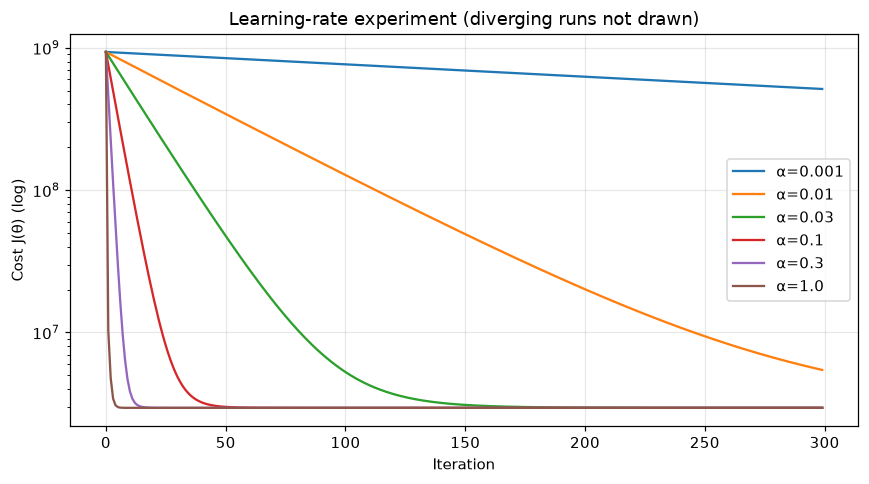

,alpha,final cost after 300 it.,status
0,0.001,5.131357e+08,converging
1,0.010,5.455283e+06,converging
2,0.030,2.954196e+06,converging
3,0.100,2.953974e+06,converging
4,0.300,2.953974e+06,converging
5,1.000,2.953974e+06,converging
6,3.000,3.821381e+30,DIVERGED


In [3]:
alphas = [0.001, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0]
fig, ax = plt.subplots(figsize=(8, 4.5))
rows = []
for a in alphas:
    th, h = gradient_descent(Xtr, y_train, alpha=a, lam=LAMBDA, n_iters=300)
    diverged = (not np.isfinite(h[-1])) or len(h) < 300 or h[-1] > h[0]
    rows.append({"alpha": a, "final cost after 300 it.": float(h[-1]) if np.isfinite(h[-1]) else float("inf"),
                 "status": "DIVERGED" if diverged else "converging"})
    if not diverged:
        ax.plot(h, label=f"α={a}")
ax.set_yscale("log"); ax.set_xlabel("Iteration"); ax.set_ylabel("Cost J(θ) (log)"); ax.set_title("Learning-rate experiment (diverging runs not drawn)")
ax.legend(); plt.tight_layout(); savefig(fig, "q1", "exp_learning_rate"); plt.show()
lr_df = pd.DataFrame(rows); display(lr_df)
EXP["learning_rate"] = rows

## Experiment 2 — Effect of feature scaling
For each scaling method we use the **largest stable learning rate** (α = 1 / λ_max of XᵀX/m) so the comparison is fair, then count how many iterations are needed to reach within 1 % of the optimal cost.

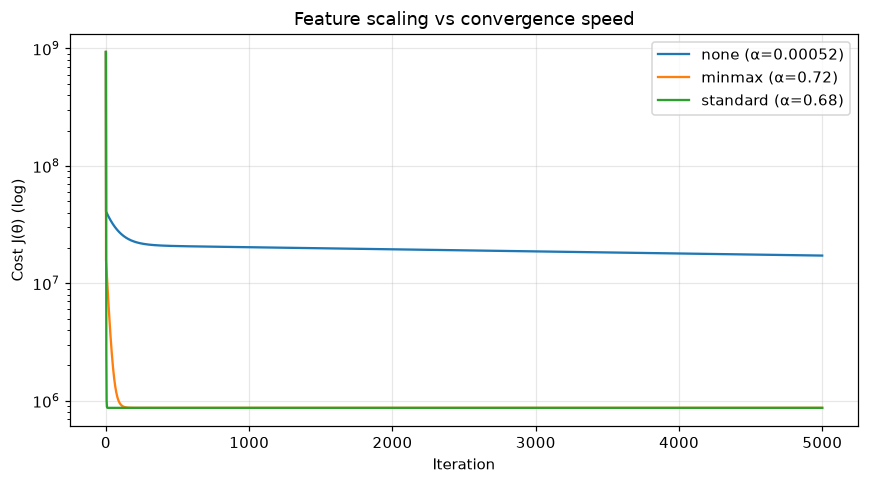

,scaling,largest stable alpha,iterations to reach 1% of optimum,test MSE after 5000 it.,test MSE closed-form
0,none,0.000525,>5000,9.176033e+07,753796.769373
1,minmax,0.716404,139,7.537968e+05,753796.769373
2,standard,0.682554,8,7.537968e+05,753796.769373


In [4]:
rows = []
fig, ax = plt.subplots(figsize=(8, 4.5))
for method in ["none", "minmax", "standard"]:
    A, B, _ = prepare(method)
    m_ = len(y_train)
    lam_max = np.linalg.eigvalsh(A.T @ A / m_).max()
    a_safe = 1.0 / lam_max
    th_star = normal_equation(A, y_train, 0.0)
    j_star = cost_function(A, y_train, th_star, 0.0)
    th, h = gradient_descent(A, y_train, alpha=a_safe, lam=0.0, n_iters=5000)
    reach = np.where(h <= j_star * 1.01 + 1e-12)[0]
    rows.append({"scaling": method, "largest stable alpha": a_safe,
                 "iterations to reach 1% of optimum": int(reach[0]) if len(reach) else ">5000",
                 "test MSE after 5000 it.": mse(y_test, B @ th),
                 "test MSE closed-form": mse(y_test, B @ th_star)})
    ax.semilogy(h, label=f"{method} (α={a_safe:.2g})")
ax.set_xlabel("Iteration"); ax.set_ylabel("Cost J(θ) (log)"); ax.set_title("Feature scaling vs convergence speed"); ax.legend()
plt.tight_layout(); savefig(fig, "q1", "exp_scaling"); plt.show()
sc_df = pd.DataFrame(rows); display(sc_df)
EXP["scaling"] = rows

## Experiment 3 — Effect of the regularisation parameter λ
λ is varied on a log grid. **Train** vs **test** MSE shows whether the model under-fits (both high) or over-fits (train low, test high).

,lambda,train MSE,test MSE,||theta[1:]||,GD vs closed-form gap
0,0.00,1.739508e+06,7.537968e+05,8.511373e+03,2.910383e-11
1,0.01,1.739547e+06,7.556221e+05,8.503940e+03,2.910383e-11
2,0.10,1.743386e+06,7.725339e+05,8.437777e+03,2.910383e-11
3,1.00,2.065878e+06,9.907790e+05,7.840480e+03,2.910383e-11
4,10.00,1.229228e+07,6.947102e+06,4.838858e+03,3.637979e-11
5,100.00,4.920619e+07,5.298522e+07,1.143620e+03,3.637979e-11
6,1000.00,1.794284e+29,4.273512e+29,3.620705e+14,3.248126e+14
7,10000.00,1.074277e+31,2.407998e+31,2.862564e+15,2.672722e+15


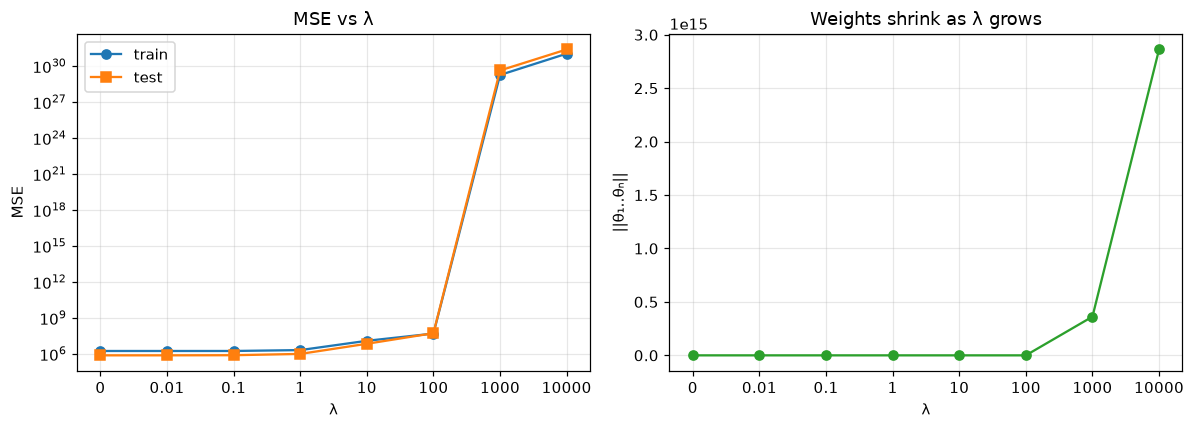

In [5]:
lams = [0, 0.01, 0.1, 1, 10, 100, 1000, 10000]
rows = []
for lam in lams:
    th = normal_equation(Xtr, y_train, lam)       # exact minimiser (same J as GD, faster for a sweep)
    thg, _ = gradient_descent(Xtr, y_train, alpha=ALPHA, lam=lam, n_iters=N_ITERS)
    rows.append({"lambda": lam, "train MSE": mse(y_train, Xtr @ thg), "test MSE": mse(y_test, Xte @ thg),
                 "||theta[1:]||": float(np.linalg.norm(thg[1:])),
                 "GD vs closed-form gap": float(np.max(np.abs(th - thg)))})
lam_df = pd.DataFrame(rows); display(lam_df)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
xs = np.arange(len(lams))
axes[0].plot(xs, lam_df["train MSE"], "o-", label="train"); axes[0].plot(xs, lam_df["test MSE"], "s-", label="test")
axes[0].set_xticks(xs); axes[0].set_xticklabels(lams); axes[0].set_xlabel("λ"); axes[0].set_ylabel("MSE"); axes[0].set_yscale("log"); axes[0].legend(); axes[0].set_title("MSE vs λ")
axes[1].plot(xs, lam_df["||theta[1:]||"], "o-", color="tab:green"); axes[1].set_xticks(xs); axes[1].set_xticklabels(lams)
axes[1].set_xlabel("λ"); axes[1].set_ylabel("||θ₁..θₙ||"); axes[1].set_title("Weights shrink as λ grows")
plt.tight_layout(); savefig(fig, "q1", "exp_lambda"); plt.show()
EXP["lambda"] = rows

## Experiment 4 — Stress test for over-fitting (small training set + polynomial features)
A plain linear model on a large dataset rarely over-fits, so λ has little to do. To **see** over-fitting and how λ cures it,
we deliberately give the model too much freedom: degree-3 polynomial features and only a small training sample.
(The model is still our own gradient-descent / closed-form code; scikit-learn is used only to generate the polynomial columns.)

polynomial degree=3, training samples used=16
number of parameters: 10  vs training examples: 16


,lambda,train MSE,test MSE
0,0.000,2.747854e+05,5.640428e+06
1,0.001,3.335770e+05,4.360969e+06
2,0.010,5.840849e+05,1.145810e+06
3,0.100,1.492218e+06,1.329555e+06
4,1.000,2.363382e+06,3.490745e+06
5,10.000,6.166130e+06,1.170302e+07
6,100.000,2.484210e+07,3.057975e+07
7,1000.000,5.724318e+07,7.087456e+07


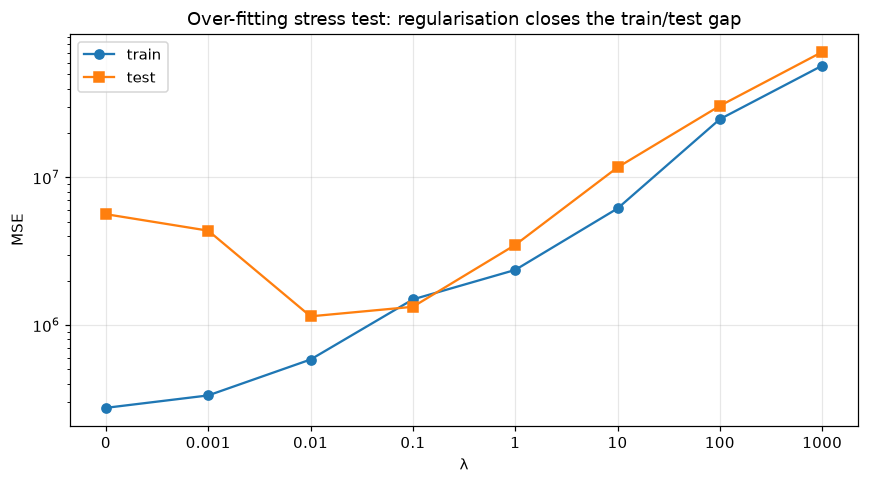

In [6]:
deg = 3 if X_df.shape[1] <= 6 else 2
n_small = max(int(0.08 * len(y_train)), 4 * X_df.shape[1] + 10)
n_small = min(n_small, len(y_train))
print(f"polynomial degree={deg}, training samples used={n_small}")
poly = PolynomialFeatures(degree=deg, include_bias=False)
Ptr_all = poly.fit_transform(X_train_raw); Pte = poly.transform(X_test_raw)
Ptr = Ptr_all[:n_small]; ytr_small = y_train[:n_small]
sc_p = fit_scaler(Ptr, "standard")
A, B = add_bias(apply_scaler(Ptr, sc_p)), add_bias(apply_scaler(Pte, sc_p))
print("number of parameters:", A.shape[1], " vs training examples:", A.shape[0])

lams2 = [0, 0.001, 0.01, 0.1, 1, 10, 100, 1000]
rows = []
for lam in lams2:
    th = normal_equation(A, ytr_small, lam) if lam > 0 else np.linalg.lstsq(A, ytr_small, rcond=None)[0]
    rows.append({"lambda": lam, "train MSE": mse(ytr_small, A @ th), "test MSE": mse(y_test, B @ th)})
st_df = pd.DataFrame(rows); display(st_df)
fig, ax = plt.subplots(figsize=(8, 4.5)); xs = np.arange(len(lams2))
ax.plot(xs, st_df["train MSE"], "o-", label="train"); ax.plot(xs, st_df["test MSE"], "s-", label="test")
ax.set_xticks(xs); ax.set_xticklabels(lams2); ax.set_xlabel("λ"); ax.set_ylabel("MSE"); ax.set_yscale("log")
ax.set_title("Over-fitting stress test: regularisation closes the train/test gap"); ax.legend()
plt.tight_layout(); savefig(fig, "q1", "exp_overfit"); plt.show()
best = st_df.loc[st_df["test MSE"].idxmin()]
EXP["overfit_stress_test"] = {"degree": deg, "n_train": int(n_small), "n_params": int(A.shape[1]),
                              "rows": rows, "best_lambda": float(best["lambda"])}

## Save

In [ ]:
save_json(EXP, ROOT / "results" / "q1" / "experiments.json")
print("Saved results/q1/experiments.json ✔  — Question 1 notebooks are finished.")

Saved results/q1/experiments.json ✔  — Question 1 notebooks are finished.


: 